In [32]:
# Uruchom tę komórkę raz, aby udostępnić moduły pomocnicze warsztatów.
import io
import os
import sys
import zipfile
from pathlib import Path
from urllib.request import urlopen

# Pobierz wszystkie pliki repozytorium, w tym moduły pomocnicze, raz na sesję Colaba.
if "google.colab" in sys.modules:
    REPO_DIR = Path("/content/Data-Analysis-Workshop-main")
    if not REPO_DIR.is_dir():
        archive_url = "https://github.com/bajon1/Data-Analysis-Workshop/archive/refs/heads/main.zip"
        with urlopen(archive_url, timeout=60) as response:
            with zipfile.ZipFile(io.BytesIO(response.read())) as archive:
                archive.extractall(REPO_DIR.parent)
else:
    REPO_DIR = Path.cwd()
    if REPO_DIR.name == "notebooks":
        REPO_DIR = REPO_DIR.parent

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
print(f"Repozytorium warsztatów: {REPO_DIR}")


Repozytorium warsztatów: C:\Users\piotr\Projects\Data-Analysis-Workshop


# Warsztaty analizy danych

## Czego się nauczysz

Na przykładzie rzeczywistej ankiety przećwiczysz odczytywanie tabeli, wybieranie odpowiedzi, obsługę brakujących danych i tworzenie czytelnych wykresów. Nie zakładamy wcześniejszej znajomości programowania.

Kurs wykorzystuje [ankietę OSMI dotyczącą zdrowia psychicznego w branży technologicznej](https://www.kaggle.com/datasets/osmi/mental-health-in-tech-survey), opisaną przez autorów jako badanie z 2014 roku. Opisujemy warunki pracy i deklarowane wsparcie. Nie diagnozujemy respondentów ani nie szacujemy częstości występowania zaburzeń psychicznych.

Ćwiczenia dotyczą niewielkiego zestawu pytań o miejsce pracy. Płeć, wiek, lokalizacja, historia rodzinna, historia leczenia i komentarze tekstowe nie wchodzą do tabeli ćwiczeniowej. Pełny słownik poniżej opisuje plik źródłowy, ale nie wykorzystujemy tych pól w analizach.

Uruchom raz komórkę pomocniczą powyżej, a następnie przechodź kolejno przez części 0–3. Dalsze części dotyczą wycieku danych, pracy z LLM i przykładów na wymyślonym tekście.


## Część 0: Przygotowanie — pobieramy tabelę

**DataFrame** to tabela: jeden wiersz odpowiada jednej odpowiedzi na ankietę, a jedna kolumna — jednemu pytaniu. Poniższa komórka pobiera plik `survey.csv` z Kaggle i odczytuje go do tabeli o nazwie `df_raw`.

`kagglehub` wskazuje pobrany plik, a `pd.read_csv(...)` go otwiera. Repozytorium nie zawiera zbioru danych. Plik jest na tyle mały, że możemy odczytać go w całości.

Dopiero kolejna komórka wybierze kolumny do ćwiczeń. Nie wyświetlamy wierszy z pełnej ankiety.


In [33]:
%pip -q install kagglehub

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

data_file = kagglehub.dataset_download(
    "osmi/mental-health-in-tech-survey",
    path="survey.csv",
)
df_raw = pd.read_csv(data_file)
print("Odpowiedzi na ankietę:", len(df_raw))



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Odpowiedzi na ankietę: 1259


### Nasza tabela robocza

W całej części praktycznej korzystamy z tych samych sześciu kolumn.

| Kolumna | Znaczenie w kursie | Co ćwiczymy |
|---|---|---|
| `remote_work` | Praca zdalna przez co najmniej połowę czasu | Wybór grupy i porównywanie odsetków |
| `self_employed` | Deklarowane samozatrudnienie | Wyszukiwanie i oznaczanie brakujących odpowiedzi |
| `benefits` | Deklarowane świadczenia pracodawcy dotyczące zdrowia psychicznego | Zliczanie odpowiedzi i tworzenie wykresu |
| `care_options` | Znajomość możliwości opieki zapewnianych przez pracodawcę | Odróżnianie wiedzy od dostępności |
| `wellness_program` | Poruszanie tematu zdrowia psychicznego w firmowym programie wspierania zdrowia | Modyfikowanie wykresu |
| `seek_help` | Zasoby pracodawcy dotyczące zdrowia psychicznego i szukania pomocy | Zastosowanie znanego wzorca do innego pytania |

Są to deklaracje respondentów, a nie audyt polityki pracodawcy. Odpowiedź „nie wiem” ma własne znaczenie i powinna pozostać widoczna.

Zachowujemy oryginalny zapis odpowiedzi w pliku: `Yes` — tak, `No` — nie, `Don't know` — nie wiem, `Not sure` — nie mam pewności. Dzięki temu kod odpowiada danym źródłowym.

Poniższy wybór tworzy osobną tabelę `df`. Znaczenie nawiasów wyjaśnimy w części 1.


In [34]:
workshop_columns = [
    "remote_work",
    "self_employed",
    "benefits",
    "care_options",
    "wellness_program",
    "seek_help",
]

df = df_raw[workshop_columns].copy()
df.head()


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
0,No,NaN,Yes,Not sure,No,Yes
1,No,NaN,Don't know,No,Don't know,Don't know
2,No,NaN,No,No,No,No
3,No,NaN,No,Yes,No,No
4,Yes,NaN,Yes,No,Don't know,Don't know


### Słownik kolumn pliku źródłowego

Poniższe opisy pytań opierają się na załączniku do zadania i [karcie danych autorów](https://www.kaggle.com/datasets/osmi/mental-health-in-tech-survey). Dokumentują źródło; nie są listą cech, które należy przekazać modelowi predykcyjnemu.

| Kolumna | Opis |
|---|---|
| `Timestamp` | Czas przesłania odpowiedzi na ankietę. |
| `Age` | Wiek. |
| `Gender` | Płeć. |
| `Country` | Kraj. |
| `state` | Stan lub terytorium, jeśli respondent mieszka w Stanach Zjednoczonych. |
| `self_employed` | Czy pracujesz na własny rachunek? |
| `family_history` | Czy w Twojej rodzinie występowały zaburzenia psychiczne? |
| `treatment` | Czy szukałeś lub szukałaś leczenia w związku ze zdrowiem psychicznym? |
| `work_interfere` | Jeśli doświadczasz problemów ze zdrowiem psychicznym, czy utrudniają Ci one pracę? |
| `no_employees` | Ile osób zatrudnia Twoja firma lub organizacja? |
| `remote_work` | Czy pracujesz zdalnie, poza biurem, przez co najmniej 50% czasu? |
| `tech_company` | Czy Twój pracodawca jest przede wszystkim firmą lub organizacją technologiczną? |
| `benefits` | Czy pracodawca zapewnia świadczenia dotyczące zdrowia psychicznego? |
| `care_options` | Czy znasz możliwości opieki w zakresie zdrowia psychicznego zapewniane przez pracodawcę? |
| `wellness_program` | Czy pracodawca omawiał zdrowie psychiczne w ramach programu wspierania zdrowia pracowników? |
| `seek_help` | Czy pracodawca udostępnia materiały dotyczące zdrowia psychicznego i szukania pomocy? |
| `anonymity` | Czy przy korzystaniu ze wsparcia dotyczącego zdrowia psychicznego lub używania substancji chroniona jest anonimowość? |
| `leave` | Jak łatwo jest uzyskać zwolnienie lub urlop z powodu problemów ze zdrowiem psychicznym? |
| `mental_health_consequence` | Czy rozmowa z pracodawcą o zdrowiu psychicznym mogłaby mieć negatywne konsekwencje? |
| `phys_health_consequence` | Czy rozmowa z pracodawcą o zdrowiu fizycznym mogłaby mieć negatywne konsekwencje? |
| `coworkers` | Czy byłbyś skłonny lub byłabyś skłonna rozmawiać ze współpracownikami o zdrowiu psychicznym? |
| `supervisor` | Czy byłbyś skłonny lub byłabyś skłonna rozmawiać z bezpośrednim przełożonym o zdrowiu psychicznym? |
| `mental_health_interview` | Czy poruszyłbyś lub poruszyłabyś temat zdrowia psychicznego podczas rozmowy kwalifikacyjnej? |
| `phys_health_interview` | Czy poruszyłbyś lub poruszyłabyś temat zdrowia fizycznego podczas rozmowy kwalifikacyjnej? |
| `mental_vs_physical` | Czy pracodawca traktuje zdrowie psychiczne równie poważnie jak zdrowie fizyczne? |
| `obs_consequence` | Czy słyszałeś lub słyszałaś o negatywnych konsekwencjach dla współpracowników z problemami zdrowia psychicznego albo je zaobserwowałeś lub zaobserwowałaś? |
| `comments` | Dodatkowe komentarze tekstowe. Nie używamy ich w kursie. |

`treatment` opisuje deklarowane szukanie leczenia, **a nie diagnozę**. Plik źródłowy zawiera również dane osobiste i potencjalnie identyfikujące; samo wybranie podzbioru kolumn nie dowodzi anonimowości. Uczestnicy zgłaszali się do badania samodzielnie, dlatego odsetki opisują zebrane odpowiedzi, a nie wszystkich pracowników.


## Część 1: Czytamy Pythona — funkcje, metody i nawiasy

### Wywoływanie funkcji i metod

Nawiasy okrągłe `()` oznaczają **wykonaj tę operację**. Wartości wewnątrz to dane wejściowe, czyli argumenty.

| Przykład | Jak go odczytać |
|---|---|
| `len(df)` | Wywołaj **funkcję** `len`, przekazując jej tabelę. |
| `print("Cześć")` | Wywołaj **funkcję** `print`, przekazując jej tekst. |
| `df.head(3)` | Wywołaj **metodę** `head` należącą do `df`, prosząc o 3 wiersze. |
| `df.head()` | Wywołaj tę samą metodę z domyślną liczbą wierszy. |
| `df.shape` | Odczytaj **atrybut**: liczbę wierszy i kolumn. Bez nawiasów okrągłych. |

Funkcję zapisujemy jako `funkcja(argument)`, a metodę jako `obiekt.metoda(argument)`. Kropka może też wskazywać bibliotekę: `pd.read_csv(plik)` jest funkcją z pandas, a nie metodą tabeli.

`=` zapisuje wartość pod daną nazwą. To coś innego niż `==`, które sprawdza, czy dwie wartości są równe.


In [35]:
print("Liczba wierszy:", len(df))
print("Wiersze i kolumny:", df.shape)
df.head(3)


Liczba wierszy: 1259
Wiersze i kolumny: (1259, 6)


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
0,No,NaN,Yes,Not sure,No,Yes
1,No,NaN,Don't know,No,Don't know,Don't know
2,No,NaN,No,No,No,No


### Ćwiczenie 1: zmień argument

Wyświetl pierwsze **2** wiersze tabeli roboczej i wypisz, ile zawiera odpowiedzi.

**Podpowiedź:** Wykorzystaj dwie operacje z przykładu. Zmień liczbę wewnątrz `head(...)`; argumentem `len(...)` nadal jest `df`.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

```python
print("Liczba wierszy:", len(df))
df.head(2)
```

</details>


In [36]:
print("Liczba wierszy:", len(df))
# Zmień liczbę poniżej.
df.head(3)


Liczba wierszy: 1259


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
0,No,NaN,Yes,Not sure,No,Yes
1,No,NaN,Don't know,No,Don't know,Don't know
2,No,NaN,No,No,No,No


### Nawiasy kwadratowe służą do wybierania

Nawiasy kwadratowe `[]` oznaczają **wybierz**, a nie wywołaj.

Python numeruje pozycje od **0**. W małej liście poniżej `answers[0]` wybiera pierwszy element. Fragment `answers[0:2]` zawiera pozycje 0 i 1; końcowa pozycja 2 jest pomijana.

W tabeli `df["benefits"]` wybiera jedną kolumnę jako obiekt Series. Aby zachować kilka kolumn w tabeli, umieść listę nazw wewnątrz nawiasów tabeli: `df[["benefits", "care_options"]]`.

Cudzysłowy oznaczają tekst. Pisownia i wielkość liter w nazwach kolumn muszą się zgadzać.


In [37]:
answers = ["Yes", "No", "Don't know"]
print("Pierwsza odpowiedź:", answers[0])
print("Pierwsze dwie odpowiedzi:", answers[0:2])

df[["benefits", "care_options"]].head(3)


Pierwsza odpowiedź: Yes
Pierwsze dwie odpowiedzi: ['Yes', 'No']


,benefits,care_options
0,Yes,Not sure
1,Don't know,No
2,No,No


### Ćwiczenie 2: wybierz dwa pytania

Pokaż pierwsze 5 wierszy kolumn **remote_work** i **wellness_program**, w tej kolejności.

**Podpowiedź:** Zachowaj podwójne nawiasy kwadratowe z przykładu. Zmień tylko dwie nazwy kolumn w cudzysłowach oraz argument `head`.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

```python
df[["remote_work", "wellness_program"]].head(5)
```

</details>


In [38]:
# Zmień nazwy kolumn i liczbę wierszy.
df[["benefits", "care_options"]].head(3)


,benefits,care_options
0,Yes,Not sure
1,Don't know,No
2,No,No


### Wybieramy wiersze za pomocą pytania

`df["remote_work"] == "Yes"` zadaje pytanie dla każdego wiersza. Wynikiem są wartości `True` i `False`, czyli prawda i fałsz.

Umieszczenie tego wyniku wewnątrz `df[...]` zachowuje wiersze oznaczone jako `True`. Czytaj poniższy przykład w dwóch krokach: **zadaj pytanie**, a następnie **zachowaj pasujące wiersze**. Nie potrzebujemy specjalnej metody indeksowania wierszy.


In [39]:
works_remotely = df["remote_work"] == "Yes"
remote_workers = df[works_remotely]
remote_workers.head(3)


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
4,Yes,NaN,Yes,No,Don't know,Don't know
6,Yes,NaN,No,No,No,No
7,Yes,NaN,No,Yes,No,No


### Ćwiczenie 3: zmień wybór

Pokaż pierwsze 3 odpowiedzi osób, które odpowiedziały **No** na pytanie `remote_work`.

**Podpowiedź:** Wykorzystaj filtr w dwóch krokach. Pytanie pozostaje to samo; zmień dopasowywaną odpowiedź z `"Yes"` na `"No"`.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

```python
office_rows = df["remote_work"] == "No"
df[office_rows].head(3)
```

</details>


In [40]:
# Dostosuj odpowiedź; możesz też zmienić nazwy zmiennych.
matching_rows = df["remote_work"] == "Yes"
df[matching_rows].head(3)


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
4,Yes,NaN,Yes,No,Don't know,Don't know
6,Yes,NaN,No,No,No,No
7,Yes,NaN,No,Yes,No,No


## Część 2: Czyszczenie — zobacz problem, zanim zmienisz tabelę

### Zliczamy brakujące odpowiedzi

`isna()` oznacza brakujące wartości jako `True`, a `sum()` zlicza te oznaczenia. Obie operacje są metodami. Czytając `df.isna().sum()` od lewej do prawej, otrzymujemy: **znajdź braki, a następnie policz je w każdej kolumnie**.

Brak odpowiedzi to coś innego niż `"Don't know"`, `"Not sure"` lub `"No"`. Są to zapisane odpowiedzi, a nie brakujące wartości.

Pytanie `self_employed` pozwala pokazać rzeczywiste braki bez korzystania z danych demograficznych.


remote_work          0
self_employed       18
benefits             0
care_options         0
wellness_program     0
seek_help            0
dtype: int64


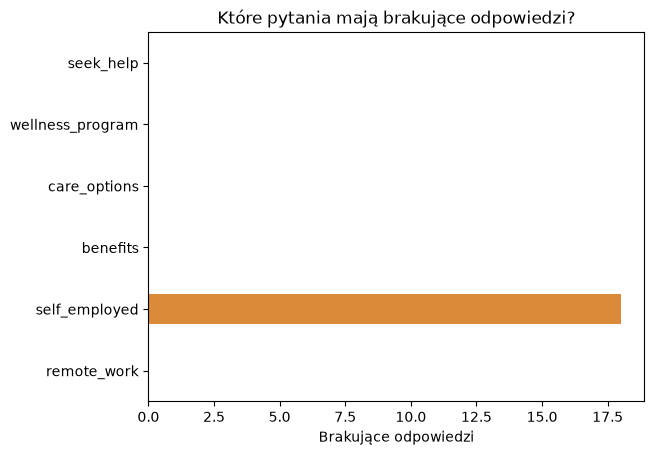

In [41]:
missing_answers = df.isna().sum()
print(missing_answers)

missing_answers.plot.barh(color="#d98b39")
plt.xlabel("Brakujące odpowiedzi")
plt.title("Które pytania mają brakujące odpowiedzi?")
plt.show()


### Ćwiczenie 4: sprawdź jedno pytanie

Policz brakujące odpowiedzi wyłącznie w **self_employed**.

**Podpowiedź:** Najpierw wybierz kolumnę za pomocą `df["..."]`. Następnie zastosuj ten sam łańcuch `.isna().sum()` co powyżej.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

```python
df["self_employed"].isna().sum()
```

</details>


In [42]:
# Zmień wybrane pytanie.
df["remote_work"].isna().sum()


np.int64(0)

### Oznaczamy braki bez zgadywania odpowiedzi

Zanim zmienisz rzeczywiste dane, wypróbuj operację na trzech wymyślonych odpowiedziach. `pd.Series(...)` tworzy pojedynczą kolumnę. `fillna("Brak odpowiedzi")` nadaje etykietę jej pustemu elementowi.

Jest to sposób prezentacji braku, a nie oszacowanie, co dana osoba odpowiedziałaby na pytanie. Operacja nie zmienia `"Yes"`, `"No"` ani odpowiedzi wyrażających niepewność.

`copy()` tworzy osobną tabelę roboczą, dzięki czemu oryginał pozostaje dostępny do porównań.


In [43]:
example_answers = pd.Series(["Yes", None, "No"])
example_answers.fillna("Brak odpowiedzi")


0                Yes
1    Brak odpowiedzi
2                 No
dtype: str

### Ćwiczenie 5: oznacz brakujące odpowiedzi

Utwórz osobną tabelę **df_clean**, zastępując wyłącznie braki w `df` etykietą **"Brak odpowiedzi"**.

**Podpowiedź:** W przykładzie użyliśmy `.fillna("Brak odpowiedzi")` dla jednej kolumny. Ta sama metoda działa też na całej tabeli: wywołaj ją na `df` i zapisz wynik przez `df_clean = ...`.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

```python
df_clean = df.fillna("Brak odpowiedzi")
df_clean.head(3)
```

</details>


In [44]:
# Zmień operację po prawej stronie na podstawie przykładu powyżej.
df_clean = df.copy()
df_clean.head(3)


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
0,No,NaN,Yes,Not sure,No,Yes
1,No,NaN,Don't know,No,Don't know,Don't know
2,No,NaN,No,No,No,No


### Kontynuujemy ze wspólnej tabeli roboczej

Po sprawdzeniu ćwiczenia 5 uruchom poniższą komórkę, aby dalsze przykłady zaczynały się od tej samej oczyszczonej tabeli.

`value_counts()` zlicza każdą zapisaną odpowiedź. `dropna=False` oznacza, że należy pokazać również braki, jeśli jakieś pozostały. Argumenty nazwane zapisujemy jako `nazwa=wartość` wewnątrz nawiasów okrągłych.

**Nie usuwaj powtarzających się wierszy** tylko dlatego, że ktoś udzielił tych samych sześciu odpowiedzi. Różni respondenci mogą zgodnie z prawdą wybrać takie same kategorie.


In [45]:
df_clean = df.fillna("Brak odpowiedzi")
df_clean["self_employed"].value_counts(dropna=False)


self_employed
No                 1095
Yes                 146
Brak odpowiedzi      18
Name: count, dtype: int64

### Ćwiczenie 6: zachowaj odpowiedzi wyrażające niepewność

Policz odpowiedzi na **care_options**. Zachowaj widoczne **"Not sure"** i wyjaśnij, dlaczego nie należy zamieniać tej odpowiedzi na **"No"**.

**Podpowiedź:** Wybierz inną kolumnę i wykorzystaj `.value_counts(dropna=False)`. Zliczaj zapisane etykiety; nieznajomość odpowiedzi to coś innego niż stwierdzenie, że świadczenie jest niedostępne.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

```python
df_clean["care_options"].value_counts(dropna=False)
```

</details>


In [46]:
# Zmień kolumnę; zachowaj metodę zliczania.
df_clean["self_employed"].value_counts(dropna=False)


self_employed
No                 1095
Yes                 146
Brak odpowiedzi      18
Name: count, dtype: int64

## Część 3: Opisujemy i wizualizujemy — jedno pytanie naraz

### Zliczamy odpowiedzi i rysujemy wykres słupkowy

Zacznij od konkretnego pytania: **Co respondenci deklarują na temat świadczeń pracodawcy dotyczących zdrowia psychicznego?**

Zapisz liczebności odpowiedzi, a następnie je narysuj. `plot.barh()` tworzy poziome słupki, których długość odpowiada liczebności. Funkcje `plt` opisują wykres. Zmiana tytułu zmienia podpis, a nie dane.

Zachowaj na wykresie `"Don't know"`. Ta odpowiedź opisuje brak wiedzy o wsparciu, a nie dowodzi, że wsparcia nie ma.


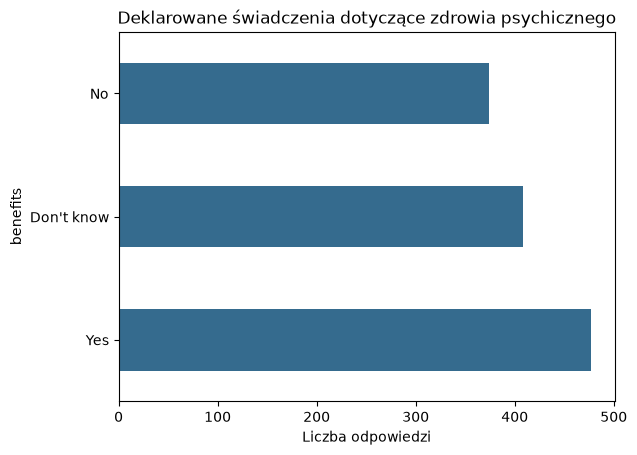

In [47]:
benefit_counts = df_clean["benefits"].value_counts()
benefit_counts.plot.barh(color="#356b8e")
plt.xlabel("Liczba odpowiedzi")
plt.title("Deklarowane świadczenia dotyczące zdrowia psychicznego")
plt.show()


### Ćwiczenie 7: dostosuj wykres

Narysuj taki sam wykres słupkowy dla **wellness_program**. Nadaj mu tytuł wskazujący, którego pytania dotyczy.

**Podpowiedź:** Skopiuj wzorzec z przykładu. Zmień kolumnę, użyj nowej zmiennej z liczebnościami i popraw tytuł. Operacje rysowania i opisywania wykresu pozostają takie same.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

```python
wellness_counts = df_clean["wellness_program"].value_counts()
wellness_counts.plot.barh(color="#356b8e")
plt.xlabel("Liczba odpowiedzi")
plt.title("Deklarowane rozmowy o zdrowiu w programie firmowym")
plt.show()
```

</details>


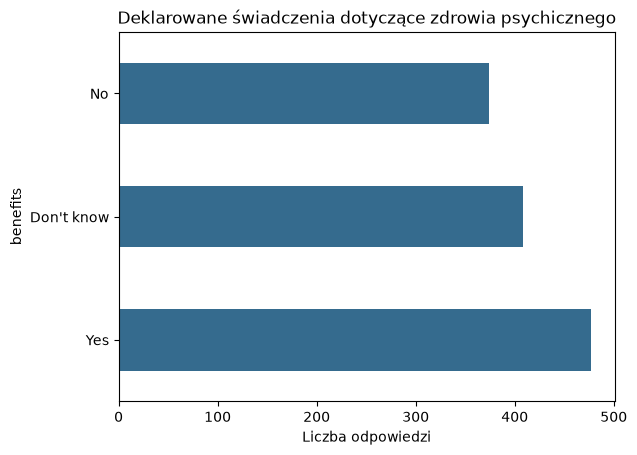

In [48]:
# Dostosuj kolumnę, zmienną z liczebnościami i tytuł.
counts = df_clean["benefits"].value_counts()
counts.plot.barh(color="#356b8e")
plt.xlabel("Liczba odpowiedzi")
plt.title("Deklarowane świadczenia dotyczące zdrowia psychicznego")
plt.show()


### Liczebności i procenty odpowiadają na różne pytania

`value_counts(normalize=True)` zwraca udziały zamiast liczebności. Mnożenie przez 100 zamienia udział na procent, a `round(1)` wyświetla jedno miejsce po przecinku.

Mianownik stanowią tutaj **wszystkie wiersze df_clean**, w tym odpowiedzi „nie wiem” i „Brak odpowiedzi”. Nie usuwaj tych kategorii bez wyraźnej zmiany interpretacji.

Opisuj wynik jako odsetek **odpowiedzi w tej ankiecie**. Samodzielne zgłaszanie się uczestników oznacza, że próba nie daje reprezentatywnego oszacowania dla wszystkich pracowników branży technologicznej.


In [49]:
benefit_percent = df_clean["benefits"].value_counts(normalize=True) * 100
print("Mianownik:", len(df_clean), "odpowiedzi")
benefit_percent.round(1)


Mianownik: 1259 odpowiedzi


benefits
Yes           37.9
Don't know    32.4
No            29.7
Name: proportion, dtype: float64

### Ćwiczenie 8: wykorzystaj obliczanie procentów

Pokaż procenty odpowiedzi dla **seek_help**, zaokrąglone do jednego miejsca po przecinku. Wskaż mianownik.

**Podpowiedź:** Użyj tego samego wzorca `.value_counts(normalize=True) * 100`. Zmień pytanie i nazwę zmiennej, a potem wywołaj `.round(1)`.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

```python
help_percent = df_clean["seek_help"].value_counts(normalize=True) * 100
print("Mianownik:", len(df_clean), "odpowiedzi")
help_percent.round(1)
```

</details>


In [50]:
# Zmień pytanie na seek_help.
percentages = df_clean["benefits"].value_counts(normalize=True) * 100
print("Mianownik:", len(df_clean), "odpowiedzi")
percentages.round(1)


Mianownik: 1259 odpowiedzi


benefits
Yes           37.9
Don't know    32.4
No            29.7
Name: proportion, dtype: float64

### Porównujemy grupy, nie myląc ich wielkości ze wsparciem

Pytanie: **Jak różnią się deklaracje o świadczeniach między osobami pracującymi zdalnie a pozostałymi?**

`pd.crosstab(pierwsza_kolumna, druga_kolumna)` jest **funkcją** pandas. Zlicza kombinacje odpowiedzi: pierwsze pytanie opisuje wiersze, a drugie — kolumny. Najpierw obejrzyj liczebności, żeby zobaczyć wielkości grup.


In [51]:
benefits_by_remote_counts = pd.crosstab(
    df_clean["remote_work"],
    df_clean["benefits"],
)
benefits_by_remote_counts


benefits,Don't know,No,Yes
remote_work,,,
No,282,241,360
Yes,126,133,117


Dodanie `normalize="index"` przelicza każdy wiersz na udziały wewnątrz danej grupy. Po pomnożeniu przez 100 każdy wiersz sumuje się do 100%.

`stacked=True` łączy kategorie odpowiedzi w jeden słupek dla każdej grupy. Porównywanie udziałów pomaga, gdy grupy mają różną liczbę odpowiedzi. Sprawdź też tabelę liczebności: procenty w małej grupie mogą być niestabilne.


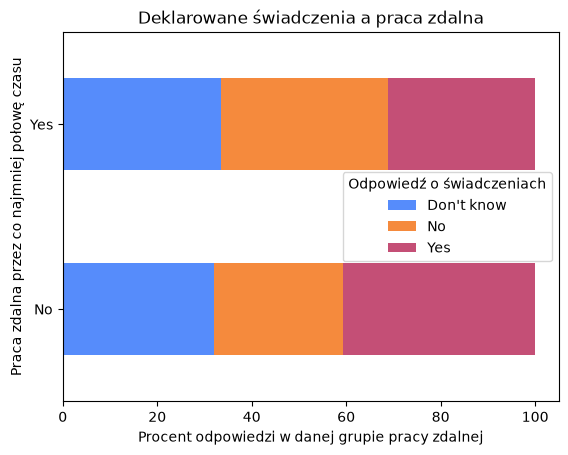

In [52]:
benefits_by_remote_percent = pd.crosstab(
    df_clean["remote_work"],
    df_clean["benefits"],
    normalize="index",
) * 100

benefits_by_remote_percent.plot.barh(stacked=True)
plt.xlabel("Procent odpowiedzi w danej grupie pracy zdalnej")
plt.ylabel("Praca zdalna przez co najmniej połowę czasu")
plt.title("Deklarowane świadczenia a praca zdalna")
plt.legend(title="Odpowiedź o świadczeniach")
plt.show()


### Ćwiczenie 9: połącz znane kroki

Porównaj odpowiedzi na **wellness_program** między grupami pracy zdalnej. Wyświetl tabelę liczebności, a następnie wykres procentów wewnątrz grup.

**Podpowiedź:** Połącz dwa przykłady z `crosstab`. Zachowaj `remote_work` jako pierwszą kolumnę, zastąp `benefits` przez `wellness_program`, a `normalize="index"` pozostaw wyłącznie w tabeli procentowej.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

```python
wellness_by_remote_counts = pd.crosstab(
    df_clean["remote_work"], df_clean["wellness_program"]
)
display(wellness_by_remote_counts)

wellness_by_remote_percent = pd.crosstab(
    df_clean["remote_work"],
    df_clean["wellness_program"],
    normalize="index",
) * 100
wellness_by_remote_percent.plot.barh(stacked=True)
plt.xlabel("Procent odpowiedzi w danej grupie pracy zdalnej")
plt.ylabel("Praca zdalna przez co najmniej połowę czasu")
plt.title("Deklarowane rozmowy o zdrowiu a praca zdalna")
plt.legend(title="Odpowiedź o programie zdrowotnym")
plt.show()
```

</details>


benefits,Don't know,No,Yes
remote_work,,,
No,282,241,360
Yes,126,133,117


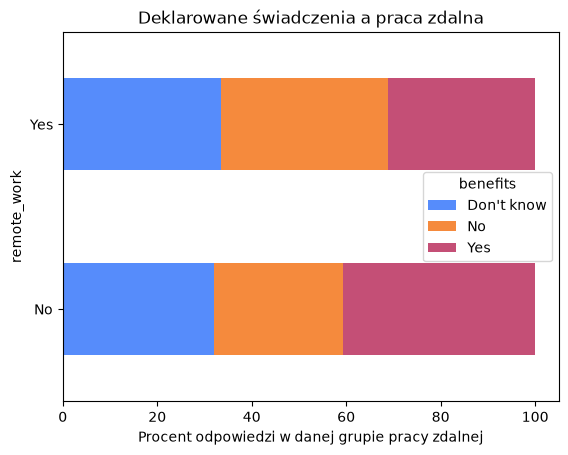

In [53]:
# Dostosuj obie nazwy drugiej kolumny i podpisy wykresu.
group_counts = pd.crosstab(df_clean["remote_work"], df_clean["benefits"])
display(group_counts)

group_percent = pd.crosstab(
    df_clean["remote_work"],
    df_clean["benefits"],
    normalize="index",
) * 100
group_percent.plot.barh(stacked=True)
plt.xlabel("Procent odpowiedzi w danej grupie pracy zdalnej")
plt.title("Deklarowane świadczenia a praca zdalna")
plt.show()


### Ćwiczenie 10: interpretuj wykres, a nie diagnozę

Napisz dwa zdania o jednym ze swoich wykresów:

1. Opisz zaobserwowany wzorzec odpowiedzi, wskazując pytanie i mianownik.
2. Podaj jeden powód, dla którego to porównanie nie dowodzi przyczynowego wpływu pracy zdalnej.

**Podpowiedź:** Użyj sformułowania „wśród odpowiedzi w tej ankiecie”. Weź pod uwagę samodzielne zgłaszanie się uczestników, nierówne wielkości grup, niezmierzone różnice między pracodawcami i odpowiedzi wyrażające niepewność. Nie wnioskuj o niczyjej diagnozie na podstawie wykresu.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

Poprawna odpowiedź nazywa przedstawione kategorie i grupy, wskazuje mianownik i nie stwierdza, że praca zdalna spowodowała różnicę. Ankieta jest badaniem obserwacyjnym z doborem przez samodzielne zgłoszenie; sama zależność nie ustala związku przyczynowego.

</details>


## Część 4: Wyciek danych — co było wiadomo wcześniej?

**Wyciek danych** występuje wtedy, gdy zadanie predykcyjne korzysta z informacji, które nie byłyby dostępne w zamierzonym momencie przewidywania. Model może przez to sprawiać wrażenie trafnego z niewłaściwego powodu. Zobacz [wskazówki scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

Załóżmy, że ktoś chce przewidywać `treatment`: „Czy szukałeś lub szukałaś leczenia w związku ze zdrowiem psychicznym?”. To informacja o szukaniu leczenia, a nie diagnoza ani obiektywna miara potrzeby pomocy.

Niektóre odpowiedzi opisują wiedzę lub postrzeganie wsparcia w miejscu pracy, m.in. `mental_health_consequence`, `mental_health_interview`, `benefits` i `care_options`. Osoba, która już szukała pomocy, mogła dowiedzieć się więcej o dostępnych możliwościach albo zetknąć się z negatywnymi reakcjami w pracy. Odpowiedzi zapisane **po** takim doświadczeniu mogą odzwierciedlać wynik, który próbujemy przewidzieć. Model może nauczyć się tej konsekwencji lub jej pośredniego wskaźnika zamiast użytecznej informacji wcześniejszej — nawet zależności niemal tautologicznej.

Jest to **ryzyko wymagające sprawdzenia**, a nie dowód, że każda cecha dotycząca wsparcia powoduje wyciek. Na przykład świadczenia mogły istnieć przed szukaniem leczenia. Ten przekrojowy zbiór danych nie ustala potrzebnej kolejności zdarzeń. Sama wysoka trafność nie rozwiązuje tego problemu.

| Proponowana cecha | O co trzeba zapytać? |
|---|---|
| `mental_health_consequence` | Czy opinię zapisano przed doświadczeniem szukania leczenia, czy po nim? |
| `mental_health_interview` | Czy to wcześniejsza postawa, czy pogląd ukształtowany przez doświadczenia leczenia i ujawniania problemów? |
| `benefits` lub `care_options` | Czy wsparcie lub wiedza o nim istniały i mogły zostać zmierzone przed zamierzonym momentem przewidywania? |
| Udokumentowana polityka pracodawcy zmierzona przed szukaniem pomocy | Czy rzeczywiście jest to wcześniejsza informacja i czy pasuje do postawionego zadania? |

W rzetelnym badaniu predykcyjnym najpierw określ moment przewidywania, zmienną docelową, badaną populację i dozwolone informacje. Korzystaj z pomiarów prospektywnych lub udokumentowanych pomiarów sprzed wyniku; nie zakładaj, że ta ankieta je zapewnia. Wydziel dane do oceny przed dopasowaniem przetwarzania wstępnego. Tam, gdzie to istotne, nie pozwól, aby ta sama osoba lub pracodawca pojawiali się po obu stronach podziału.

Nasze wykresy są **opisowe**, dlatego możemy omawiać deklarowane wsparcie bez budowania klasyfikatora szukania leczenia.


### Ćwiczenie 11: sprawdź kuszący predyktor

Współpracownik twierdzi, że wykorzystanie `mental_health_consequence`, `mental_health_interview` i `benefits` do przewidywania `treatment` na pewno jest użyteczne, ponieważ klasyfikator jest trafny.

Wypisz dwa pytania, które zadasz przed zaakceptowaniem takiego wyniku. Następnie wyjaśnij, dlaczego `benefits` nie jest automatycznie dowiedzionym źródłem wycieku.

**Podpowiedź:** Skorzystaj z tabeli powyżej. Zapytaj, kiedy każda odpowiedź była dostępna i czy szukanie leczenia mogło na nią wpłynąć. Odróżnij możliwe wyjaśnienie przyczynowe od udokumentowanej kolejności zdarzeń.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

Zapytaj, czy każdą cechę zmierzono przed momentem przewidywania i czy wcześniejsze leczenie mogło wpłynąć na odpowiedź. Świadczenia mogły rzeczywiście poprzedzać szukanie pomocy, ale sama ankieta nie dowodzi, kiedy zmierzono wsparcie pracodawcy lub wiedzę respondenta o nim. Trafność nie potwierdza poprawnej kolejności czasowej ani użyteczności klinicznej.

</details>


## Część 5: Poproś LLM o kod bez udostępniania odpowiedzi

Korzystaj z LLM jako pomocnika w pisaniu kodu. Przekaż zadanie, nazwy kolumn i typy danych, a zaproponowany kod wykonaj we własnej sesji. Nie musisz wklejać wierszy ankiety.

`df_clean.dtypes` opisuje typy kolumn. Poniższy kod zamienia na tekst wyłącznie ten opis. Nawiasy klamrowe w napisie `f"..."` wstawiają schemat i zadanie do polecenia dla modelu.

Przy rzeczywistych danych badawczych przestrzegaj zgód, zasad instytucji i reguł korzystania z zatwierdzonych narzędzi. Wybór kolumn, usunięcie nazwisk lub zamaskowanie kilku wzorców nie gwarantują anonimowości.


In [54]:
schema = df_clean.dtypes.astype(str).to_string()
task = "Napisz kod pandas zliczający odpowiedzi benefits, z zachowaniem kategorii Don't know."

prompt = f"""Zaproponuj kod Pythona; nie wymyślaj wyników.
Zadanie: {task}
Nazwy kolumn i typy danych:
{schema}
Nie dołączono wierszy respondentów.
Wyjaśnij mianownik i zachowaj widoczne odpowiedzi wyrażające niepewność.
"""
print(prompt)


Zaproponuj kod Pythona; nie wymyślaj wyników.
Zadanie: Napisz kod pandas zliczający odpowiedzi benefits, z zachowaniem kategorii Don't know.
Nazwy kolumn i typy danych:
remote_work         str
self_employed       str
benefits            str
care_options        str
wellness_program    str
seek_help           str
Nie dołączono wierszy respondentów.
Wyjaśnij mianownik i zachowaj widoczne odpowiedzi wyrażające niepewność.



### Ćwiczenie 12: doprecyzuj polecenie

Dostosuj zdanie opisujące zadanie, aby poprosić o **procenty odpowiedzi seek_help**, z uwzględnieniem niepewnych odpowiedzi i opisanym poziomym wykresem słupkowym.

**Podpowiedź:** Zmień tylko tekst w `task`; komórka powtarza wcześniejszy kod budowania polecenia. Wystarczą nazwy kolumn i typy. Nie dołączaj `df.head()` ani komentarzy z ankiety.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

```python
task = (
    "Napisz kod pandas obliczający procenty odpowiedzi seek_help i tworzący opisany poziomy "
    "wykres słupkowy. Zachowaj Don't know i Brak odpowiedzi oraz podaj mianownik."
)

prompt = f"""Zaproponuj kod Pythona; nie wymyślaj wyników.
Zadanie: {task}
Nazwy kolumn i typy danych:
{schema}
Nie dołączono wierszy respondentów.
Wyjaśnij mianownik i zachowaj widoczne odpowiedzi wyrażające niepewność.
"""
print(prompt)
```

</details>


In [55]:
# Zmień opis zadania i uruchom komórkę, aby zbudować nowe polecenie.
task = "Napisz kod pandas zliczający odpowiedzi benefits, z zachowaniem kategorii Don't know."

prompt = f"""Zaproponuj kod Pythona; nie wymyślaj wyników.
Zadanie: {task}
Nazwy kolumn i typy danych:
{schema}
Nie dołączono wierszy respondentów.
Wyjaśnij mianownik i zachowaj widoczne odpowiedzi wyrażające niepewność.
"""
print(prompt)


Zaproponuj kod Pythona; nie wymyślaj wyników.
Zadanie: Napisz kod pandas zliczający odpowiedzi benefits, z zachowaniem kategorii Don't know.
Nazwy kolumn i typy danych:
remote_work         str
self_employed       str
benefits            str
care_options        str
wellness_program    str
seek_help           str
Nie dołączono wierszy respondentów.
Wyjaśnij mianownik i zachowaj widoczne odpowiedzi wyrażające niepewność.



### Sprawdź zaproponowany kod

Porównaj proponowane operacje z przykładami, które już wykonałeś lub wykonałaś. Sprawdź, czy LLM nie zmienił mianownika, nie odrzucił niepewnych odpowiedzi, nie wymyślił kolumn i nie sformułował twierdzeń przyczynowych.

Korzystaj z [dokumentacji pandas](https://pandas.pydata.org/docs/) oraz pomocy i podpowiedzi w IDE, aby sprawdzić nieznaną metodę. Przy szukaniu błędu udostępniaj komunikat o błędzie i mały **wymyślony** przykład zamiast wielokrotnego przesyłania rzeczywistej tabeli.

Schemat również wymaga sprawdzenia: same nazwy kolumn mogą ujawniać poufny temat badania. Przykłady tekstowe poniżej są wymyślone i nie dotyczą respondentów.


## Część 6: Maskowanie i automatyczne wykrywanie — tylko wymyślony tekst

Kolumna `comments` z ankiety jest wykluczona. Maskowanie pokazujemy na wymyślonym zdaniu. Zdanie jest po angielsku, ponieważ opcjonalny analizator w dalszym przykładzie korzysta z angielskiego modelu językowego.

`re.sub(wzorzec, zamiennik, tekst)` jest funkcją zastępującą fragmenty pasujące do wzorca. Poniższy wzorzec adresu e-mail jest przykładem, a nie kompletnym wykrywaczem danych identyfikujących.


In [56]:
import re

synthetic_text = "Contact Alex Example at alex@example.org or +48 123 456 789."
email_pattern = r"[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}"

masked_text = re.sub(email_pattern, "[EMAIL]", synthetic_text)
print(masked_text)


Contact Alex Example at [EMAIL] or +48 123 456 789.


Dla konkretnego wymyślonego formatu telefonu `+48 123 456 789` użyj wzorca `r"\+48 \d{3} \d{3} \d{3}"`. Zapis `\d{3}` oznacza trzy cyfry. Wzorzec nie obejmuje wszystkich krajowych formatów numerów.

Ta sama funkcja `re.sub(...)` może wykonać drugą zamianę na tekście, w którym adres e-mail został już zamaskowany.


### Ćwiczenie 13: połącz dwie zamiany

Zaczynając od **masked_text**, zastąp wymyślony numer telefonu etykietą **[TELEFON]**. Adres e-mail ma pozostać zamaskowany.

**Podpowiedź:** Wykorzystaj `re.sub(wzorzec, zamiennik, tekst)`. Użyj pokazanego wzorca telefonu, `"[TELEFON]"` jako zamiennika i `masked_text` jako tekstu wejściowego.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

```python
phone_pattern = r"\+48 \d{3} \d{3} \d{3}"
phone_masked = re.sub(phone_pattern, "[TELEFON]", masked_text)
print(phone_masked)
```

</details>


In [57]:
# Zmień wzorzec i zamiennik; zachowaj masked_text jako tekst wejściowy.
phone_masked = re.sub(email_pattern, "[EMAIL]", masked_text)
print(phone_masked)


Contact Alex Example at [EMAIL] or +48 123 456 789.


### Opcjonalnie: Microsoft Presidio

Presidio może wskazać dodatkowe encje, ale jego wynik zależy od zainstalowanych modeli językowych i wykrywaczy. Dwie kolejne komórki są opcjonalną demonstracją. Korzystają z tego samego wymyślonego zdania, a nie odpowiedzi na ankietę.

Mały angielski model spaCy jest pobierany z oficjalnego wydania. Automatyczne wykrywanie może przeoczyć nazwiska, identyfikatory pośrednie lub szczegóły kontekstowe; nie gwarantuje anonimizacji.


In [ ]:
# OPCJONALNIE: zainstaluj biblioteki do demonstracji na wymyślonym tekście.
%pip -q install presidio-analyzer presidio-anonymizer
%pip -q install https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl


In [ ]:
# OPCJONALNIE: uruchom po komórce instalującej Presidio.
from presidio_analyzer import AnalyzerEngine
from presidio_analyzer.nlp_engine import NlpEngineProvider
from presidio_anonymizer import AnonymizerEngine

nlp_engine = NlpEngineProvider(
    nlp_configuration={
        "nlp_engine_name": "spacy",
        "models": [{"lang_code": "en", "model_name": "en_core_web_sm"}],
    }
).create_engine()
analyzer = AnalyzerEngine(nlp_engine=nlp_engine, supported_languages=["en"])
findings = analyzer.analyze(
    text=synthetic_text,
    language="en",
    entities=["PERSON", "EMAIL_ADDRESS", "PHONE_NUMBER"],
)
print(AnonymizerEngine().anonymize(text=synthetic_text, analyzer_results=findings).text)


## Część 7: Słowa i znaczenie — kolejny wymyślony przykład

**Worek słów** (Bag of Words) zlicza słowa bez rozumienia ich znaczenia ani kolejności. Tabela liczebności pozwala zobaczyć, jak działa.

Poniższe angielskie zdania o wsparciu w miejscu pracy są wymyślone i służą jako dane przykładowe. Nie są komentarzami z ankiety. `fit_transform` uczy się słownika i tworzy liczebności. `get_feature_names_out()` zwraca poznane słowa.


In [58]:
from sklearn.feature_extraction.text import CountVectorizer

sentences = [
    "the company offers mental health support",
    "the company offers mental health help",
    "I work from home",
    "I work remotely",
]

vectorizer = CountVectorizer(ngram_range=(1, 1))
word_counts = vectorizer.fit_transform(sentences)
word_table = pd.DataFrame(
    word_counts.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=sentences,
)
word_table


,company,from,health,help,home,mental,offers,remotely,support,the,work
the company offers mental health support,1,0,1,0,0,1,1,0,1,1,0
the company offers mental health help,1,0,1,1,0,1,1,0,0,1,0
I work from home,0,1,0,0,1,0,0,0,0,0,1
I work remotely,0,0,0,0,0,0,0,1,0,0,1


**N-gram** to sekwencja sąsiadujących słów. `ngram_range=(1, 1)` zlicza tylko pojedyncze słowa, a `ngram_range=(1, 2)` — zarówno pojedyncze słowa, jak i frazy dwuwyrazowe.

Fraza „mental health” („zdrowie psychiczne”) może być użyteczna jako całość. Same liczebności słów nadal nie wskazują, że „work from home” i „work remotely” opisują podobny sposób pracy.


### Ćwiczenie 14: zmień jeden parametr

Utwórz ponownie tabelę liczebności tak, aby obejmowała pojedyncze słowa i frazy dwuwyrazowe. Odszukaj **mental health** w jej kolumnach.

**Podpowiedź:** Użyj tych samych zdań, wywołania `fit_transform` i konstrukcji DataFrame. Zmień tylko `ngram_range` z `(1, 1)` na wariant pokazany powyżej.

<details>
<summary>Sprawdź po samodzielnej próbie</summary>

```python
phrase_vectorizer = CountVectorizer(ngram_range=(1, 2))
phrase_counts = phrase_vectorizer.fit_transform(sentences)
pd.DataFrame(
    phrase_counts.toarray(),
    columns=phrase_vectorizer.get_feature_names_out(),
    index=sentences,
)
```

</details>


In [59]:
# Zmień ngram_range; pozostałe kroki są takie same jak w przykładzie.
phrase_vectorizer = CountVectorizer(ngram_range=(1, 1))
phrase_counts = phrase_vectorizer.fit_transform(sentences)
pd.DataFrame(
    phrase_counts.toarray(),
    columns=phrase_vectorizer.get_feature_names_out(),
    index=sentences,
)


,company,from,health,help,home,mental,offers,remotely,support,the,work
the company offers mental health support,1,0,1,0,0,1,1,0,1,1,0
the company offers mental health help,1,0,1,1,0,1,1,0,0,1,0
I work from home,0,1,0,0,1,0,0,0,0,0,1
I work remotely,0,0,0,0,0,0,0,1,0,0,1


### Opcjonalnie: reprezentacje wektorowe zdań

Reprezentacje wektorowe zdań, czyli embeddings, zapisują zdania jako wektory liczb. Miara podobieństwa może umieścić parafrazy blisko siebie nawet wtedy, gdy mają niewiele wspólnych słów. Takie wyniki nie są diagnozą, miarą prawdziwości ani dowodem zależności psychologicznej.

Dwie kolejne opcjonalne komórki instalują bibliotekę i pobierają mały, wcześniej wytrenowany model. Korzystają wyłącznie z czterech wymyślonych zdań powyżej. Jeśli pobieranie jest niedostępne, omów różnicę względem zliczania słów na przedstawionych przykładach.


In [ ]:
# OPCJONALNIE: zainstaluj bibliotekę do demonstracji wektorów zdań.
%pip -q install sentence-transformers


In [ ]:
# OPCJONALNIE: pobiera wytrenowany model i używa wyłącznie wymyślonych zdań.
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("sentence-transformers/paraphrase-MiniLM-L3-v2")
embeddings = embedding_model.encode(sentences)
similarities = embedding_model.similarity(embeddings, embeddings)
pd.DataFrame(similarities.numpy(), index=sentences, columns=sentences).round(2)


## Ćwiczenie końcowe: wyjaśnij swój sposób pracy

Wyjaśnij własnymi słowami:

- czym różni się wywołanie funkcji od wywołania metody i od wyboru kolumny;
- dlaczego nie należy automatycznie łączyć odpowiedzi „nie”, „nie wiem” i braku odpowiedzi;
- jaki mianownik ma wybrany przez Ciebie wykres;
- dlaczego predyktor szukania leczenia może korzystać z informacji ukształtowanej przez sam wynik;
- co możesz przekazać asystentowi programistycznemu bez wysyłania wierszy respondentów.

**Podpowiedź:** Wróć do jednego przykładu z części 1, 2, 3, 4 i 5. Wybierz jasne pytanie opisowe i czytelny wykres zamiast nieuzasadnionego twierdzenia klinicznego lub przyczynowego.

Masz teraz odtwarzalną ścieżkę od pliku CSV do udokumentowanego porównania opisowego o jasno określonym zakresie. Przy innej ankiecie świadomie dostosuj pytanie i wybrane kolumny.
